# Grab Cut segmentation

Propose a simple method to segment a rough estimate of lateral ventricle segmentation using morphological processing and thresholding.

[Link, 5 x PNG, 137 KB](https://drive.google.com/file/u/2/d/1hnQ_PHx0LhMNCMlpwCFhXVx4fFl9j_Aq/view?usp=sharing)

Use OpenCV's graph cut method to refine segmentation boundary.

`cv::grabCut`

Input has to be BGR (3 channel)

Values for the mask parameter:
- *GC_BGD* = 0 - an obvious background pixels
- *GC_FGD* = 1 - an obvious foreground (object) pixel
- *GC_PR_BGD* = 2 - a possible background pixel
- *GC_PR_FGD* = 3  - a possible foreground pixel

An example of GrabCut algorithm: [link](https://docs.opencv.org/4.x/dd/dfc/tutorial_js_grabcut.html) (note: This example uses a defined rectangle for grabcut segmentation. In our case we want to use the mask option instead)


In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Image file names
file1 = 'images/ventricles/0.png'
file2 = 'images/ventricles/1.png'
file3 = 'images/ventricles/2.png'
file4 = 'images/ventricles/3.png'
file5 = 'images/ventricles/4.png'

In [7]:
def grabcut(file: str, t1: int = 10, t2: float = 0.5, k_size: int = 5, iters: int = 2):
    # Load image
    img = cv.imread(file)

    # Convert to grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Thresholding
    _, thresh = cv.threshold(gray, t1, 255, cv.THRESH_BINARY)
    _, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # Morphological operations
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_size, k_size))
    closing = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel, iterations=iters)

    # Difference of closing - otsu
    diff = cv.absdiff(closing, otsu)

    # Distance transform
    dist_transform = cv.distanceTransform(diff, cv.DIST_L2, 5)
    cv.normalize(dist_transform, dist_transform, 0, 1.0, cv.NORM_MINMAX)

    # Opening
    opening = cv.morphologyEx(dist_transform, cv.MORPH_OPEN, kernel, iterations=iters)

    # Second threshold for ventricle segmentation
    _, ventricles = cv.threshold(opening, t2, 1.0, cv.THRESH_BINARY)
    if np.sum(ventricles) == 0:
        print('No probable foreground found.')
        return

    # Create mask for GrabCut
    mask = np.zeros(img.shape[:2], np.uint8)
    mask[ventricles == 0] = cv.GC_PR_BGD
    mask[opening != 0] = cv.GC_PR_FGD
    mask[ventricles != 0] = cv.GC_FGD
    mask[closing == 0] = cv.GC_BGD

    # Perform GrabCut segmentation
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)
    cv.grabCut(img, mask, None, bgd_model, fgd_model, 5, cv.GC_INIT_WITH_MASK)

    # Update mask based on GrabCut segmentation
    mask = np.where((mask == cv.GC_PR_FGD) | (mask == cv.GC_FGD), 255, 0).astype('uint8')

    # Apply mask to input image to get final segmentation
    result = cv.bitwise_and(img, img, mask=mask)

    fig = plt.figure(figsize=(12, 7))
    fig.suptitle('Lateral ventricle segmentation using GrabCut', fontsize=16)
    plt.subplot(241), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('(a) Original Image'), plt.xticks([]), plt.yticks([])
    plt.subplot(242), plt.imshow(cv.cvtColor(thresh, cv.COLOR_BGR2RGB))
    plt.title(f'(b) Custom threshold t={t1}'), plt.xticks([]), plt.yticks([])
    plt.subplot(243), plt.imshow(cv.cvtColor(otsu, cv.COLOR_BGR2RGB))
    plt.title('(c) Otsu threshold'), plt.xticks([]), plt.yticks([])
    plt.subplot(244), plt.imshow(cv.cvtColor(diff, cv.COLOR_BGR2RGB))
    plt.title('(d) Difference'), plt.xticks([]), plt.yticks([])
    plt.subplot(245), plt.imshow(cv.cvtColor(dist_transform, cv.COLOR_BGR2RGB))
    plt.title('(e) Distance Transform'), plt.xticks([]), plt.yticks([])
    plt.subplot(246), plt.imshow(cv.cvtColor(ventricles, cv.COLOR_BGR2RGB))
    plt.title(f'(f) Custom threshold t={t2}'), plt.xticks([]), plt.yticks([])
    plt.subplot(247), plt.imshow(cv.cvtColor(mask, cv.COLOR_BGR2RGB))
    plt.title('(g) Segmentation mask'), plt.xticks([]), plt.yticks([])
    plt.subplot(248), plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('(h) Segmentation result'), plt.xticks([]), plt.yticks([])
    plt.show()

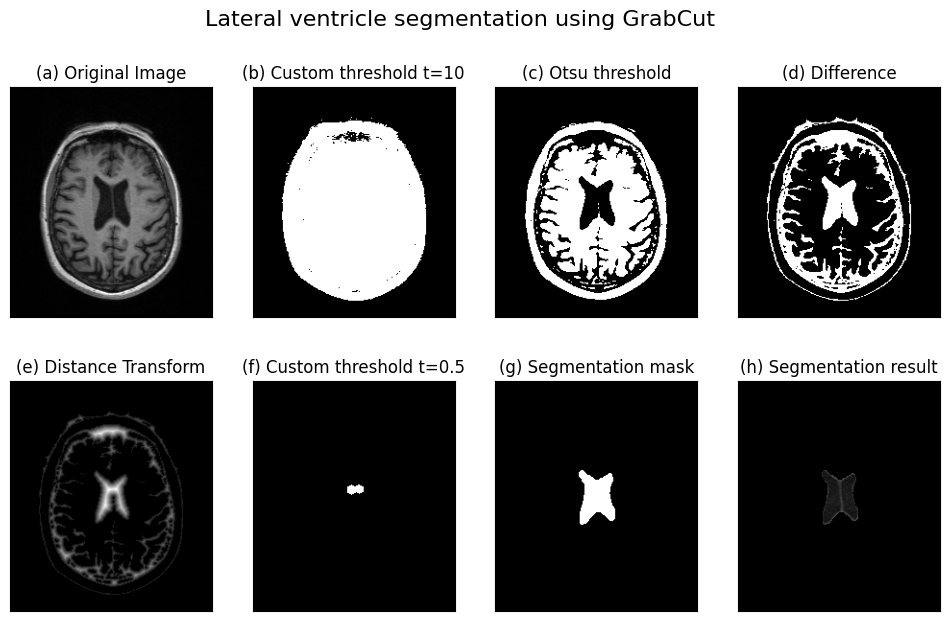

In [8]:
grabcut(file1, 10, 0.5, 5, 2)

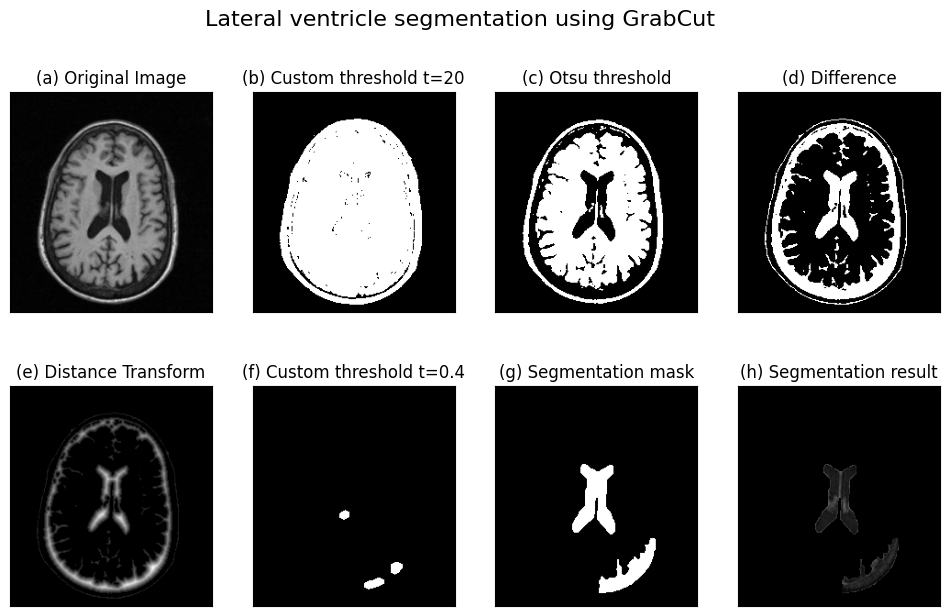

In [9]:
grabcut(file2, 20, 0.4, 5, 2)

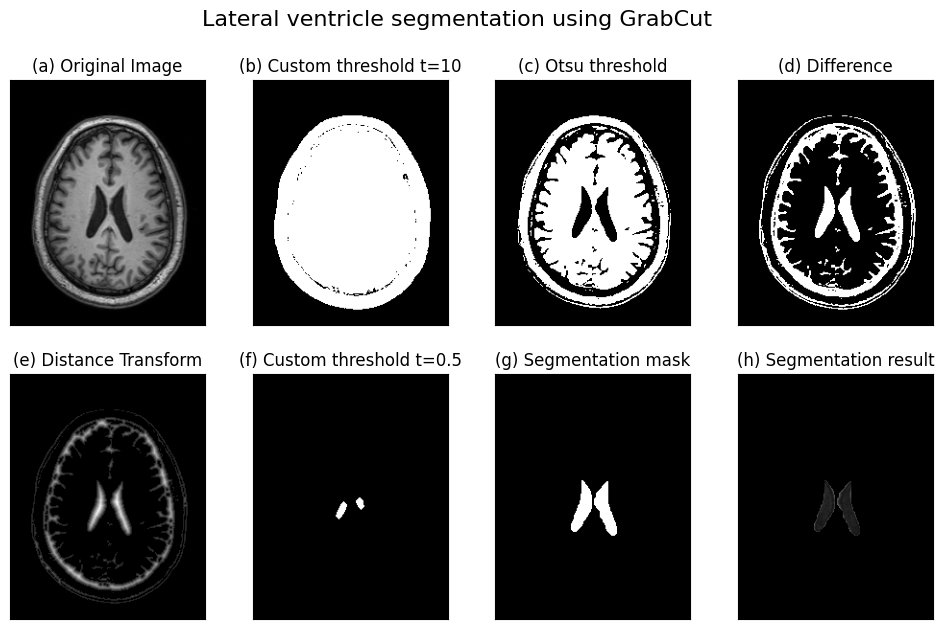

In [10]:
grabcut(file3, 10, 0.5, 3, 3)

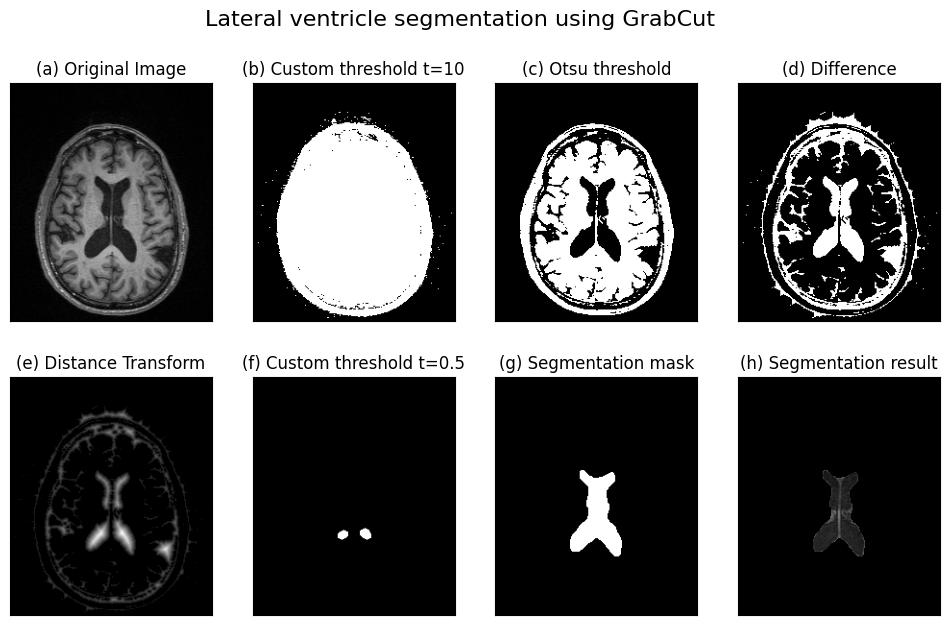

In [11]:
grabcut(file4, 10, 0.5, 5, 2)

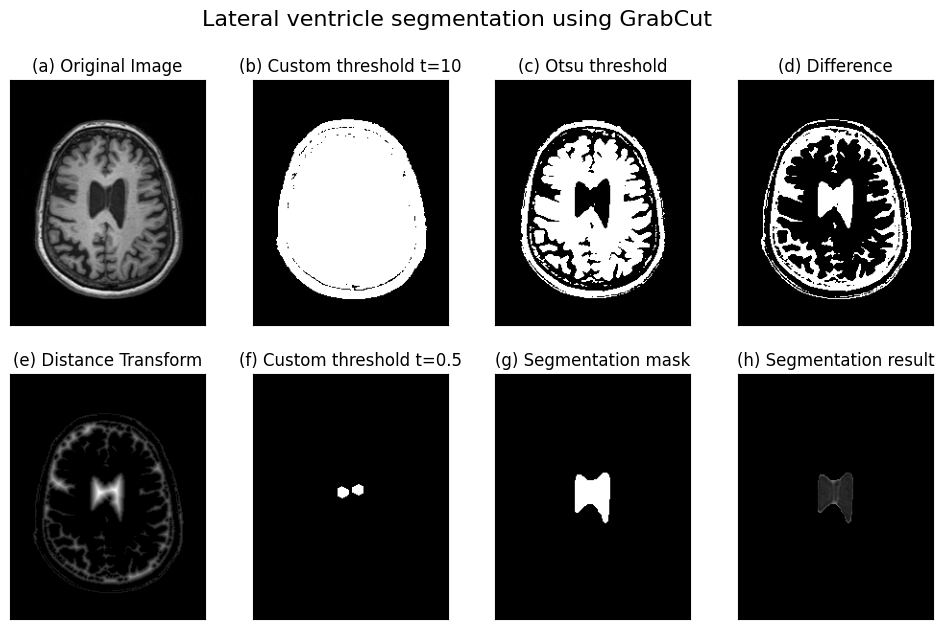

In [12]:
grabcut(file5, 10, 0.5, 5, 2)

### Interactive mask creation

In [8]:
def segment_ventricles(image, mask, num_iterations: int = 5):
    mask = np.where(mask == 255, cv.GC_FGD, cv.GC_PR_BGD).astype('uint8')

    if not np.any(mask == cv.GC_FGD):
        print('No probable foreground found.')
        return

    try:
        bgd_model = np.zeros((1, 65), np.float64)
        fgd_model = np.zeros((1, 65), np.float64)
        cv.grabCut(image, mask, None, bgd_model, fgd_model, num_iterations, cv.GC_INIT_WITH_MASK)
    except cv.error as e:
        print(e)
        return

    mask_ventricles = np.where((mask == cv.GC_PR_BGD) | (mask == cv.GC_BGD), 0, 1).astype('uint8')
    image_segmented = image * mask_ventricles[:, :, np.newaxis]

    return image_segmented


def draw_mask(event, x, y, flags, param):
    global drawing
    if event == cv.EVENT_LBUTTONDOWN:
        drawing = True

    elif event == cv.EVENT_MOUSEMOVE:
        if drawing:
            cv.circle(initial_mask, (x, y), brush_size, brush_color, -1)

    elif event == cv.EVENT_LBUTTONUP:
        drawing = False
        cv.circle(initial_mask, (x, y), brush_size, brush_color, -1)


drawing = False
brush_size = 3
brush_color = 255
img = None
initial_mask = None


def interactive_grabcut(files: list[str], scale: float = 2.0):
    global brush_size, brush_color, img, initial_mask

    idx = 0
    img = cv.imread(files[idx], cv.IMREAD_COLOR)
    img = cv.resize(img, (0, 0), fx=scale, fy=scale)

    initial_mask = np.zeros(img.shape[:2], dtype=np.uint8)
    mask_file = 'mask.png'

    window_name = 'Draw Mask'
    cv.namedWindow(window_name)
    cv.setMouseCallback(window_name, draw_mask)

    print('''
    Controls:
        - Left click and drag to draw mask
        - 'g' perform GrabCut segmentation
        - 'n' and 'p' to go to next/previous image
        - 's' and 'l' to save/load mask
        - 'c' clear the mask
        - 'b' to change brush color (black or white)
        - '+' and '-' to increase/decrease brush size
        - 'q' to quit
    ''')

    segmented = None
    while True:
        combined_image = cv.addWeighted(img, 0.7, cv.cvtColor(initial_mask, cv.COLOR_GRAY2BGR), 0.3, 0)
        cv.imshow(window_name, combined_image)

        key = cv.waitKey(1) & 0xFF

        if key == ord('q'):  # Quit
            break
        elif key == ord('g'):  # Perform grabcut segmentation
            segmented = segment_ventricles(img, initial_mask, num_iterations=10)
            if segmented is not None:
                cv.imshow('Segmented Ventricles', segmented)
        elif key == ord('c'):  # Clear the mask
            initial_mask = np.zeros(img.shape[:2], dtype=np.uint8)
        elif key == ord('s'):  # Save the mask
            cv.imwrite(mask_file, initial_mask)
        elif key == ord('l'):  # Load the mask
            try:
                initial_mask = cv.imread(mask_file, cv.IMREAD_GRAYSCALE)
                initial_mask = cv.resize(initial_mask, (0, 0), fx=scale, fy=scale)
            except cv.error as e:
                print(e)
        elif key == ord('+'):  # Increase brush size
            brush_size = min(brush_size + 1, 10)
        elif key == ord('-'):  # Decrease brush size
            brush_size = max(brush_size - 1, 1)
        elif key == ord('b'):  # Change brush color
            brush_color = 0 if brush_color == 255 else 255
        elif key == ord('n'):  # Next image
            idx = (idx + 1) % len(files)
            img = cv.imread(files[idx], cv.IMREAD_COLOR)
            img = cv.resize(img, (0, 0), fx=scale, fy=scale)
            initial_mask = np.zeros(img.shape[:2], dtype=np.uint8)
        elif key == ord('p'):  # Previous image
            idx = (idx - 1) % len(files)
            img = cv.imread(files[idx], cv.IMREAD_COLOR)
            img = cv.resize(img, (0, 0), fx=scale, fy=scale)
            initial_mask = np.zeros(img.shape[:2], dtype=np.uint8)

    cv.destroyAllWindows()

    # Plot the last image
    if segmented is not None:
        plt.figure(figsize=(10, 10))
        plt.subplot(131), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title('Original'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(initial_mask, cmap='gray')
        plt.title('GrabCut Mask'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(cv.cvtColor(segmented, cv.COLOR_BGR2RGB))
        plt.title('Segmented'), plt.xticks([]), plt.yticks([])
        plt.show()


    Controls:
        - Left click and drag to draw mask
        - 'g' perform GrabCut segmentation
        - 'n' and 'p' to go to next/previous image
        - 's' and 'l' to save/load mask
        - 'c' clear the mask
        - 'b' to change brush color (black or white)
        - '+' and '-' to increase/decrease brush size
        - 'q' to quit
    


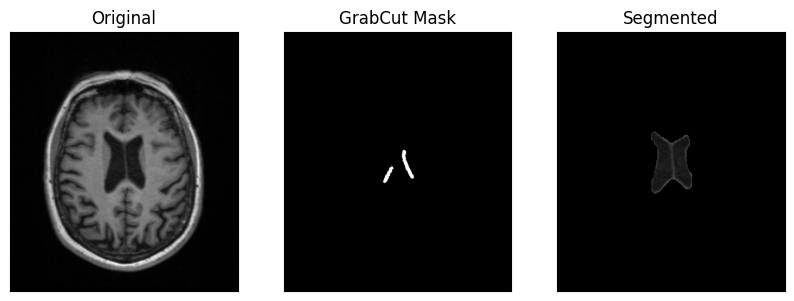

In [14]:
interactive_grabcut([file1, file2, file3, file4, file5])